# 04 — Comparison with scikit-learn (identical protocol)

All implementations are trained on **exactly the same matrices** (`dp.make_splits`, same chronological split, same winsorization and standardization estimated on the training set) with the **same hyperparameters** (α selected in notebook 02, depth and leaf size selected in notebook 03). scikit-learn is used here only as a reference.

Correspondence:
| From scratch | scikit-learn | Note |
|---|---|---|
| `LinearRegressionScratch(solver="normal")` | `LinearRegression` | same objective (α=0) |
| `LinearRegressionScratch(solver="gd", alpha=α)` | `Ridge(alpha=n·α)` | sklearn does not divide the loss by n |
| `LinearRegressionScratch(solver="sgd", alpha=α)` | `SGDRegressor(alpha=α)` | same objective; different step schedules |
| `RegressionTreeScratch(d, L)` | `DecisionTreeRegressor(max_depth=d, min_samples_leaf=L)` | same criterion (MSE) and same threshold convention |

In [1]:
import os, sys, time, warnings
sys.path.insert(0, os.path.abspath(".."))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score  # metrics are allowed
from src import data_prep as dp
from src.plot_style import *
setup()
SEED = 42
np.random.seed(SEED)
pd.set_option("display.precision", 3)
from sklearn.linear_model import LinearRegression, Ridge, SGDRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from src.scratch_linear import LinearRegressionScratch
from src.scratch_tree import RegressionTreeScratch
panel = dp.build_panel()
s = dp.make_splits(panel)
n = len(s.y_train)
# hyperparameters selected on validation in notebooks 02 and 03
ridge_val = pd.read_csv("../results/linear_performance.csv")  # (checks that 02 has been run)
grid = pd.read_csv("../results/tree_grid.csv"); best = grid.loc[grid.rmse_val.idxmin()]
BEST_D, BEST_L = int(best.max_depth), int(best.min_samples_leaf)
alphas = np.r_[0, np.logspace(-4, 1, 21)]
val_rmse = [mean_squared_error(s.y_val, LinearRegressionScratch(solver="normal", alpha=a).fit(s.X_train, s.y_train).predict(s.X_val)) ** .5 for a in alphas]
ALPHA = alphas[int(np.argmin(val_rmse))]
print(f"alpha = {ALPHA:.4g} | tree: max_depth = {BEST_D}, min_samples_leaf = {BEST_L}")

alpha = 0 | tree: max_depth = 8, min_samples_leaf = 100


In [2]:
def timed_fit(make, reps=5):
    ts = []
    for _ in range(reps):
        m = make(); t = time.perf_counter(); m.fit(s.X_train, s.y_train); ts.append(time.perf_counter() - t)
    return m, np.median(ts)

pairs = {
    "OLS": (lambda: LinearRegressionScratch(solver="normal"), lambda: LinearRegression()),
    "Ridge (GD)": (lambda: LinearRegressionScratch(solver="gd", alpha=ALPHA, lr=0.5, n_iter=10000, tol=1e-14),
                   lambda: Ridge(alpha=n * ALPHA)),
    "SGD": (lambda: LinearRegressionScratch(solver="sgd", alpha=ALPHA, lr=0.05, n_iter=60, batch_size=64, decay=0.05),
            lambda: SGDRegressor(alpha=ALPHA, penalty="l2", learning_rate="invscaling", eta0=0.01, max_iter=1000, tol=1e-6, random_state=SEED)),
    "CART tree": (lambda: RegressionTreeScratch(max_depth=BEST_D, min_samples_leaf=BEST_L),
                  lambda: DecisionTreeRegressor(max_depth=BEST_D, min_samples_leaf=BEST_L, random_state=SEED)),
}
rows, fitted = [], {}
for name, (mk_s, mk_k) in pairs.items():
    for impl, mk in [("from scratch", mk_s), ("scikit-learn", mk_k)]:
        m, t_fit = timed_fit(mk)
        fitted[(name, impl)] = m
        t = time.perf_counter(); m.predict(s.X_test); t_pred = time.perf_counter() - t
        row = {"method": name, "implementation": impl, "fit (ms)": 1e3 * t_fit, "predict (ms)": 1e3 * t_pred}
        for split in ["train", "val", "test"]:
            X, y = getattr(s, f"X_{split}"), getattr(s, f"y_{split}"); p = m.predict(X)
            row[f"MAE {split}"] = mean_absolute_error(y, p); row[f"RMSE {split}"] = mean_squared_error(y, p) ** .5; row[f"R2 {split}"] = r2_score(y, p)
        rows.append(row)
bench = pd.DataFrame(rows).set_index(["method", "implementation"])
bench.to_csv("../results/benchmark.csv")
bench[["fit (ms)", "predict (ms)", "RMSE train", "RMSE val", "MAE test", "RMSE test", "R2 test"]]

fit (ms)  predict (ms)  RMSE train  RMSE val  \
method     implementation                                                 
OLS        from scratch       0.254         0.023       4.867     4.014   
           scikit-learn       2.568         0.754       4.867     4.014   
Ridge (GD) from scratch       6.375         0.041       4.867     4.014   
           scikit-learn       1.374         0.174       4.867     4.014   
SGD        from scratch     162.578         0.025       4.867     4.017   
           scikit-learn      11.659         0.614       4.869     4.009   
CART tree  from scratch      61.901         3.567       4.807     4.080   
           scikit-learn      16.630         0.455       4.807     4.080   

                           MAE test  RMSE test  R2 test  
method     implementation                                
OLS        from scratch       1.973      3.130    0.244  
           scikit-learn       1.973      3.130    0.244  
Ridge (GD) from scratch       1.973      3.130    0.244  
           scikit-learn       1.973      3.130    0.244  
SGD        from scratch       1.972      3.130    0.245  
           scikit-learn       1.974      3.137    0.241  
CART tree  from scratch       2.138      3.314    0.153  
           scikit-learn       2.138      3.314    0.153

## Differences between implementations

In [3]:
rows = []
for name in pairs:
    a, b = fitted[(name, "from scratch")], fitted[(name, "scikit-learn")]
    d = {"method": name, "max |Δ test prediction|": np.abs(a.predict(s.X_test) - b.predict(s.X_test)).max()}
    if hasattr(b, "coef_"):
        d["max |Δ coefficient|"] = np.abs(a.coef_ - np.ravel(b.coef_)).max()
        d["|Δ bias|"] = abs(a.intercept_ - np.ravel(b.intercept_)[0])
    else:
        d["max |Δ importance|"] = np.abs(a.feature_importances_ - b.feature_importances_).max()
        d["leaves (scratch / sklearn)"] = f"{a.n_leaves()} / {b.get_n_leaves()}"
    rows.append(d)
diff = pd.DataFrame(rows).set_index("method"); diff.to_csv("../results/benchmark_diffs.csv"); diff

,max |Δ test prediction|,max |Δ coefficient|,|Δ bias|,max |Δ importance|,leaves (scratch / sklearn)
method,,,,,
OLS,3.819e-14,3.803e-15,4.441e-16,NaN,NaN
Ridge (GD),1.134e-06,1.722e-07,0.000e+00,NaN,NaN
SGD,8.989e-01,8.005e-02,9.297e-02,NaN,NaN
CART tree,3.553e-15,NaN,NaN,1.055e-14,40 / 40


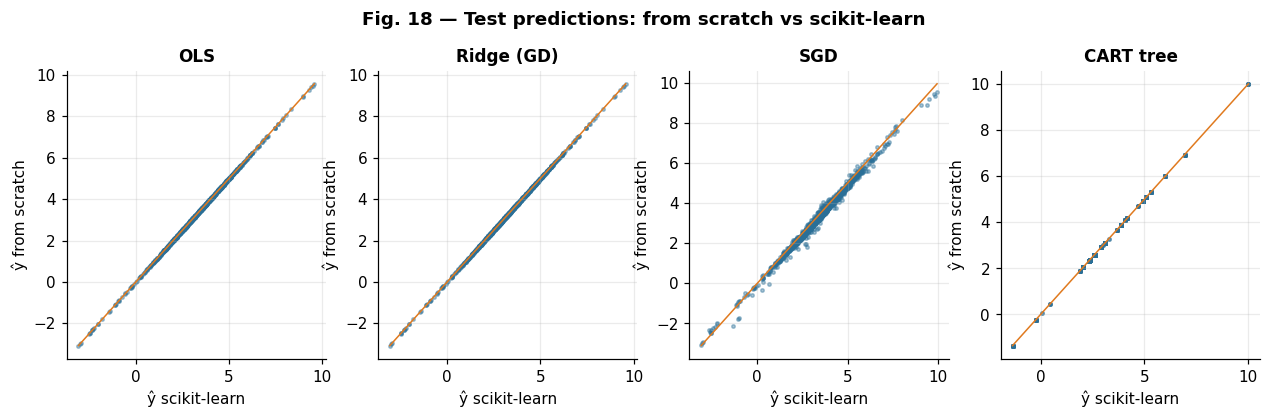

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, name in zip(axes, pairs):
    a = fitted[(name, "from scratch")].predict(s.X_test); b = fitted[(name, "scikit-learn")].predict(s.X_test)
    ax.scatter(b, a, s=5, alpha=0.4, color=C_SCRATCH)
    lim = [min(a.min(), b.min()), max(a.max(), b.max())]; ax.plot(lim, lim, color=C_SKLEARN, lw=1)
    ax.set(title=name, xlabel="ŷ scikit-learn", ylabel="ŷ from scratch")
fig.suptitle("Fig. 18 — Test predictions: from scratch vs scikit-learn", fontweight="bold", y=1.04)
save(fig, "fig18_pred_agreement.png"); plt.show()

## Positioning against references
To gauge the difficulty of the problem, we add naive baselines and a scikit-learn random forest (an ensemble of trees, not implemented here) as an indicative "ceiling".

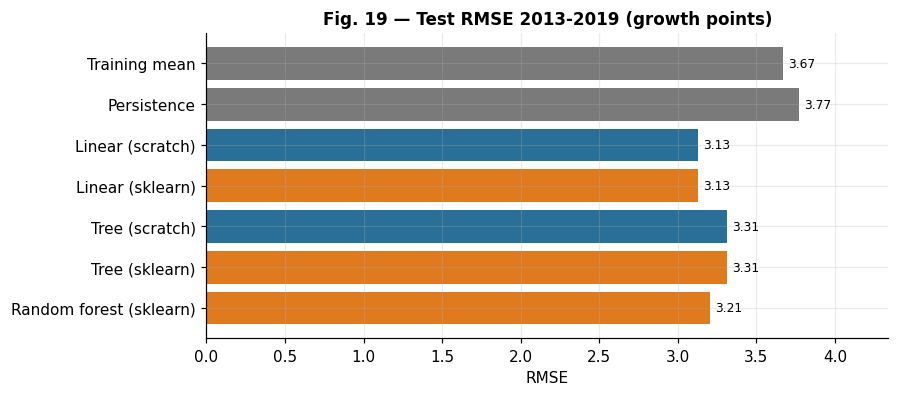

,MAE,RMSE,R2
Training mean,2.531,3.671,-0.039
Persistence,2.180,3.775,-0.099
Linear (scratch),1.973,3.130,0.244
Linear (sklearn),1.973,3.130,0.244
Tree (scratch),2.138,3.314,0.153
Tree (sklearn),2.138,3.314,0.153
Random forest (sklearn),2.056,3.208,0.206


In [5]:
lag = s.features.index("growth_lag1")
refs = {
    "Training mean": np.full_like(s.y_test, s.y_train.mean()),
    "Persistence": s.X_test[:, lag] * s.std[lag] + s.mean[lag],
    "Linear (scratch)": fitted[("Ridge (GD)", "from scratch")].predict(s.X_test),
    "Linear (sklearn)": fitted[("Ridge (GD)", "scikit-learn")].predict(s.X_test),
    "Tree (scratch)": fitted[("CART tree", "from scratch")].predict(s.X_test),
    "Tree (sklearn)": fitted[("CART tree", "scikit-learn")].predict(s.X_test),
    "Random forest (sklearn)": RandomForestRegressor(n_estimators=300, min_samples_leaf=20, random_state=SEED, n_jobs=-1).fit(s.X_train, s.y_train).predict(s.X_test),
}
summ = pd.DataFrame({k: dict(MAE=mean_absolute_error(s.y_test, p), RMSE=mean_squared_error(s.y_test, p) ** .5, R2=r2_score(s.y_test, p)) for k, p in refs.items()}).T
summ.to_csv("../results/test_summary.csv")
fig, ax = plt.subplots(figsize=(8, 3.6))
cs = [C_SCRATCH if "scratch" in k else C_SKLEARN if "sklearn" in k else C_NEUTRAL for k in summ.index]
ax.barh(summ.index, summ.RMSE, color=cs); ax.invert_yaxis()
for i, v in enumerate(summ.RMSE): ax.text(v + 0.03, i, f"{v:.2f}", va="center", fontsize=8)
ax.set(title="Fig. 19 — Test RMSE 2013-2019 (growth points)", xlabel="RMSE", xlim=(0, summ.RMSE.max() * 1.15))
save(fig, "fig19_test_rmse.png"); plt.show()
summ

## Computational cost as a function of n (tree)

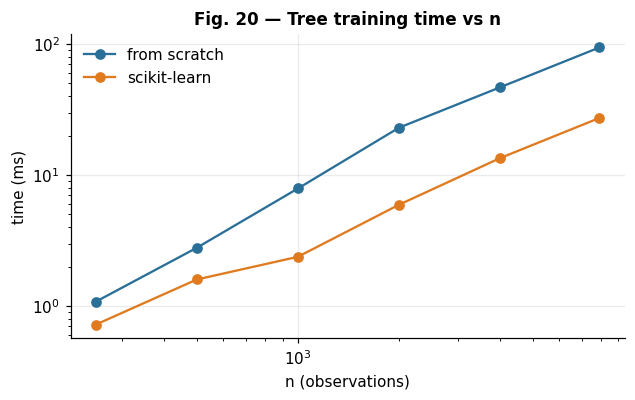

impl,from scratch,scikit-learn,ratio
n,,,
250,0.001,7.213e-04,1.495
500,0.003,1.595e-03,1.746
1000,0.008,2.377e-03,3.321
2000,0.023,5.936e-03,3.873
4000,0.047,1.347e-02,3.470
7904,0.094,2.728e-02,3.455


In [6]:
rng = np.random.default_rng(SEED); rows = []
Xb = np.vstack([s.X_train, s.X_val, s.X_test]); yb = np.r_[s.y_train, s.y_val, s.y_test]
for m in [250, 500, 1000, 2000, 4000, len(yb)]:
    idx = rng.choice(len(yb), m, replace=False)
    for impl, mk in [("from scratch", lambda: RegressionTreeScratch(max_depth=BEST_D, min_samples_leaf=BEST_L)),
                     ("scikit-learn", lambda: DecisionTreeRegressor(max_depth=BEST_D, min_samples_leaf=BEST_L))]:
        ts = []
        for _ in range(3):
            t = time.perf_counter(); mk().fit(Xb[idx], yb[idx]); ts.append(time.perf_counter() - t)
        rows.append((m, impl, np.median(ts)))
sc = pd.DataFrame(rows, columns=["n", "impl", "t"])
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for impl, c in [("from scratch", C_SCRATCH), ("scikit-learn", C_SKLEARN)]:
    d = sc[sc.impl == impl]; ax.loglog(d.n, d.t * 1e3, "o-", color=c, label=impl)
ax.set(title="Fig. 20 — Tree training time vs n", xlabel="n (observations)", ylabel="time (ms)"); ax.legend()
save(fig, "fig20_tree_scaling.png"); plt.show()
sc.pivot(index="n", columns="impl", values="t").assign(ratio=lambda d: d["from scratch"] / d["scikit-learn"])